# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [2]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [4]:
df =pd.read_csv("aviation_accidents_cleaned.csv")

df.head()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17628\3358868934.py:1: DtypeWarning: Columns (0: Event.Id) have mixed types. Specify dtype option on import or set low_memory=False.
  df =pd.read_csv("aviation_accidents_cleaned.csv")


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Event.Year,Total.Occupants,Fatal_Serious_Injuries,Aircraft.Destroyed,Make_Model
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,NaN,588.0,VMC,Probable Cause,04-12-2014,1983,NaN,NaN,0.0,BOEING 747
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,NaN,NaN,IMC,Probable Cause,02-05-2011,1983,NaN,2.0,1.0,PIPER PA-28-140
2,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,NaN,100.0,VMC,Probable Cause,11-06-2018,1983,NaN,NaN,0.0,BOEING 727-200
3,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,NaN,1.0,VMC,Probable Cause,05-05-2011,1983,NaN,NaN,0.0,BEECH C35
4,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,NaN,1.0,VMC,Probable Cause,01-02-2016,1983,NaN,NaN,0.0,CESSNA 180K


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [5]:
df["Aircraft.Size"] = np.where(
    df["Total.Occupants"] <= 20,
    "Small",
    "Large"
)

df.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Event.Year,Total.Occupants,Fatal_Serious_Injuries,Aircraft.Destroyed,Make_Model,Aircraft.Size
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,588.0,VMC,Probable Cause,04-12-2014,1983,NaN,NaN,0.0,BOEING 747,Large
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,NaN,IMC,Probable Cause,02-05-2011,1983,NaN,2.0,1.0,PIPER PA-28-140,Large
2,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,100.0,VMC,Probable Cause,11-06-2018,1983,NaN,NaN,0.0,BOEING 727-200,Large
3,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,1.0,VMC,Probable Cause,05-05-2011,1983,NaN,NaN,0.0,BEECH C35,Large
4,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,1.0,VMC,Probable Cause,01-02-2016,1983,NaN,NaN,0.0,CESSNA 180K,Large


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [18]:
# Calculate the fatal/serious injury fraction
small_aircraft["Fatal_Serious_Injury_Rate"] = (
    small_aircraft["Fatal_Serious_Injuries"] /
    small_aircraft["Total.Occupants"]
)

# Calculate statistics for each manufacturer
small_make_stats = (
    small_aircraft.groupby("Make")
    .agg(
        Mean_Injury_Rate=("Fatal_Serious_Injury_Rate", "mean"),
        Sample_Size=("Fatal_Serious_Injury_Rate", "count"),
        Mean_Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

# Keep manufacturers with at least 50 valid records
small_make_stats = small_make_stats[
    small_make_stats["Sample_Size"] >= 50
]

# Select the 15 makes with the lowest mean injury fraction
small_top15 = small_make_stats.sort_values(
    "Mean_Injury_Rate",
    ascending=True
).head(15)

small_top15

,Make,Mean_Injury_Rate,Sample_Size,Mean_Destruction_Rate
5,AVIAT AIRCRAFT INC,0.145833,72,0.042254
8,BOEING,0.156968,232,0.105882
20,MAULE,0.192593,171,0.040936
18,GRUMMAN ACFT ENG COR-SCHWEIZER,0.206897,58,0.017241
26,ROCKWELL INTERNATIONAL,0.217320,51,0.117647
15,DIAMOND AIRCRAFT IND INC,0.222973,74,0.054054
14,DEHAVILLAND,0.228263,90,0.034483
28,STINSON,0.243590,91,0.010989
1,AERONCA,0.245040,168,0.041667
7,BELLANCA,0.252825,177,0.034091


In [28]:
# Calculate the fatal/serious injury fraction
large_aircraft["Fatal_Serious_Injury_Rate"] = (
    large_aircraft["Fatal_Serious_Injuries"] /
    large_aircraft["Total.Occupants"]
)

# Calculate statistics for each manufacturer
large_make_stats = (
    large_aircraft.groupby("Make")
    .agg(
        Mean_Injury_Rate=("Fatal_Serious_Injury_Rate", "mean"),
        Sample_Size=("Fatal_Serious_Injury_Rate", "count"),
        Mean_Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

# Keep manufacturers with at least 50 valid records
large_make_stats = large_make_stats[
    large_make_stats["Sample_Size"] >= 50
]

# Select the 15 makes with the lowest mean injury fraction
large_top15 = large_make_stats.sort_values(
    "Mean_Injury_Rate",
    ascending=True
).head(15)

large_top15

,Make,Mean_Injury_Rate,Sample_Size,Mean_Destruction_Rate
2,BOEING,0.051341,486,0.082988
6,EMBRAER,0.062118,64,0.108108
0,AIRBUS,0.091539,99,0.173913


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

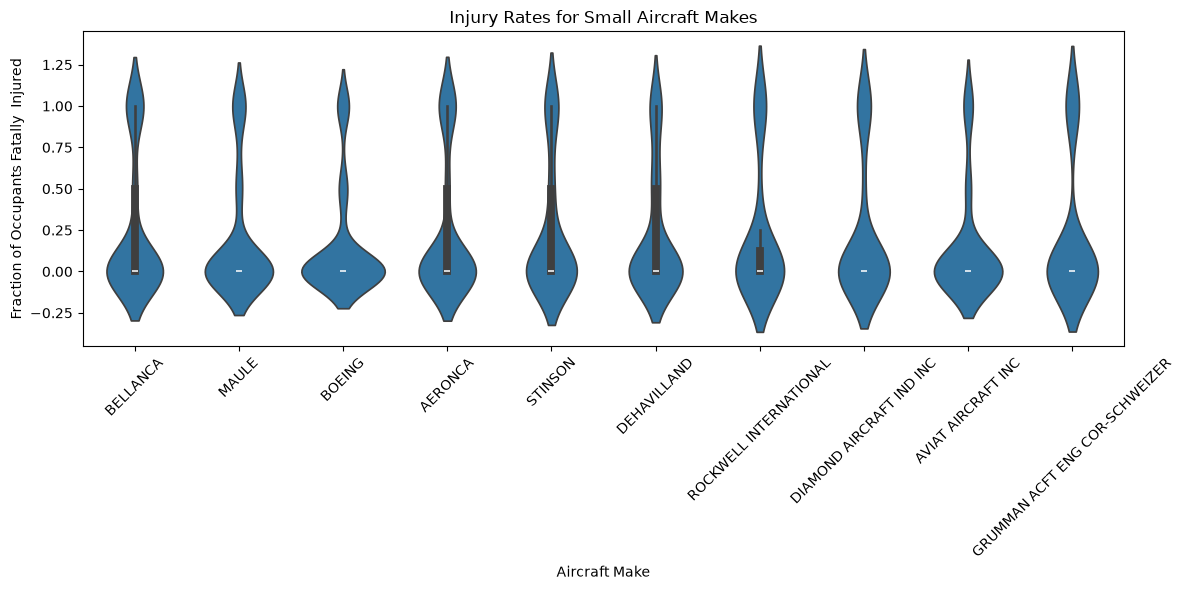

In [22]:
# The 10 makes with the lowest mean injury rates
top_10_small = small_make_stats.sort_values(
    "Mean_Injury_Rate", ascending=True
).head(10)

# Filter the data for those makes
small_data = small_aircraft[
    small_aircraft["Make"].isin(top_10_small["Make"])
]

# Plot the injury rates
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=small_data,
    x="Make",
    y="Fatal_Serious_Injury_Rate"
)

plt.title("Injury Rates for Small Aircraft Makes")
plt.xlabel("Aircraft Make")
plt.ylabel("Fraction of Occupants Fatally  Injured")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

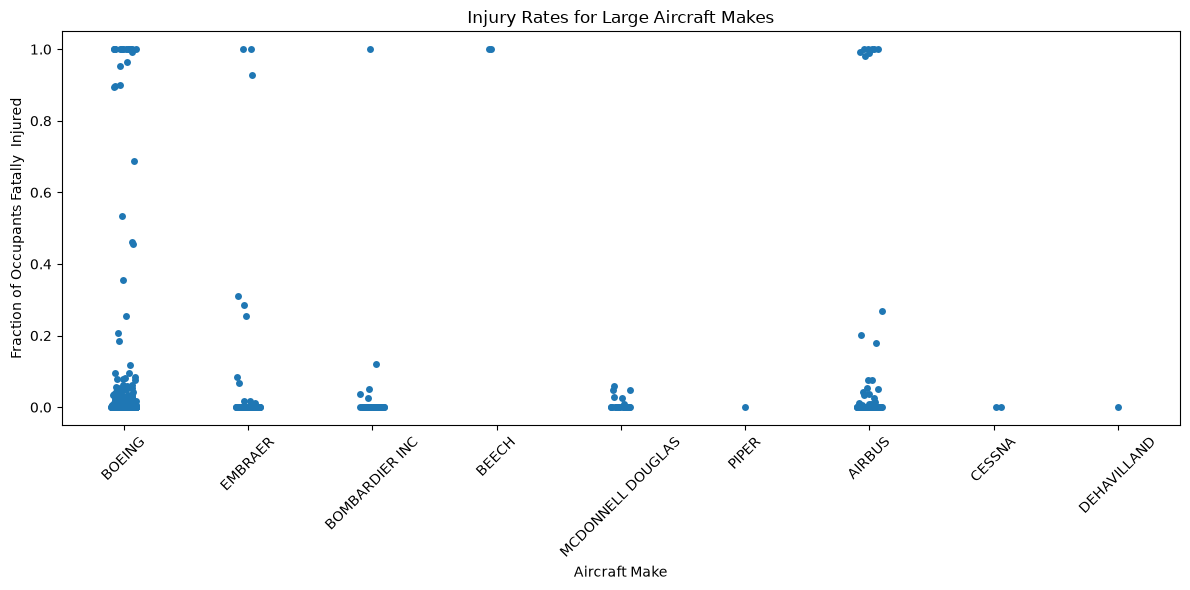

In [29]:
top_10_large = large_aircraft.groupby("Make")[
    "Fatal_Serious_Injury_Rate"
].mean().sort_values().head(10).index

large_data = large_aircraft[
    large_aircraft["Make"].isin(top_10_large)
]

plt.figure(figsize=(12, 6))

sns.stripplot(
    data=large_data,
    x="Make",
    y="Fatal_Serious_Injury_Rate",
    jitter=True
)

plt.title("Injury Rates for Large Aircraft Makes")
plt.xlabel("Aircraft Make")
plt.ylabel("Fraction of Occupants Fatally  Injured")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
large_aircraft.columns

Index(['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date',
       'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code',
       'Airport.Name', 'Injury.Severity', 'Aircraft.damage',
       'Aircraft.Category', 'Registration.Number', 'Make', 'Model',
       'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description',
       'Purpose.of.flight', 'Air.carrier', 'Total.Fatal.Injuries',
       'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured',
       'Weather.Condition', 'Report.Status', 'Publication.Date', 'Event.Year',
       'Total.Occupants', 'Fatal_Serious_Injuries', 'Aircraft.Destroyed',
       'Make_Model', 'Aircraft.Size'],
      dtype='str')

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [30]:
# Calculate destruction rates for small aircraft
small_destruction = (
    small_aircraft.groupby("Make")
    .agg(
        Destruction_Rate=("Aircraft.Destroyed", "mean"),
        Sample_Size=("Aircraft.Destroyed", "count")
    )
    .reset_index()
)

# Keep makes with at least 50 records
small_destruction = small_destruction[
    small_destruction["Sample_Size"] >= 50
]

# Select the 15 makes with the lowest destruction rates
small_destruction_top15 = small_destruction.sort_values(
    "Destruction_Rate",
    ascending=True
).head(15)

small_destruction_top15

,Make,Destruction_Rate,Sample_Size
19,LUSCOMBE,0.010753,93
28,STINSON,0.010989,91
18,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241,58
29,TAYLORCRAFT,0.032787,61
7,BELLANCA,0.034091,176
14,DEHAVILLAND,0.034483,87
20,MAULE,0.040936,171
1,AERONCA,0.041667,168
5,AVIAT AIRCRAFT INC,0.042254,71
15,DIAMOND AIRCRAFT IND INC,0.054054,74


In [31]:
# Calculate destruction rates for large aircraft
large_destruction = (
    large_aircraft.groupby("Make")
    .agg(
        Destruction_Rate=("Aircraft.Destroyed", "mean"),
        Sample_Size=("Aircraft.Destroyed", "count")
    )
    .reset_index()
)

# Keep makes with at least 50 records
large_destruction = large_destruction[
    large_destruction["Sample_Size"] >= 50
]

# Select the 15 makes with the lowest destruction rates
large_destruction_top15 = large_destruction.sort_values(
    "Destruction_Rate",
    ascending=True
).head(15)

large_destruction_top15

,Make,Destruction_Rate,Sample_Size
2,BOEING,0.082988,241


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

- For the large aircrafts Make BOEING has the least destruction rate of 8.3% out of the 241 sample size witha threshold of at least 50 records.
- It also has the least injury rate since the destruction rate is lower which make its a safer option aircraft make to choose from if you want a large aircraft.

- For the small aircraft Make LUSCOMBE has the least destruction rate of 1.02% out of the 93 sample size but has the highest injury rate noting we limited our output to 15 only.
- This brings about the conclusion that if one is choosing a small aircraft ypu have to look beyond the destruction rate.

-The violin plot shows that most small-aircraft makes have injury fractions concentrated around zero, indicating that many recorded accidents involved no fatal or serious injuries. However, some accidents had high injury fractions, showing that outcomes vary and that manufacturers should be compared using both injury rates, destruction rates, and sample sizes.

- The strip plot shows that most large-aircraft accidents resulted in low fatal/serious injury fractions, although some Boeing, Embraer, and Airbus accidents had very high injury fractions close to 1. These differences highlight the variability in accident severity, so manufacturers should be compared using their average injury rates, destruction rates, and sample sizes before making safety recommendations.



### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

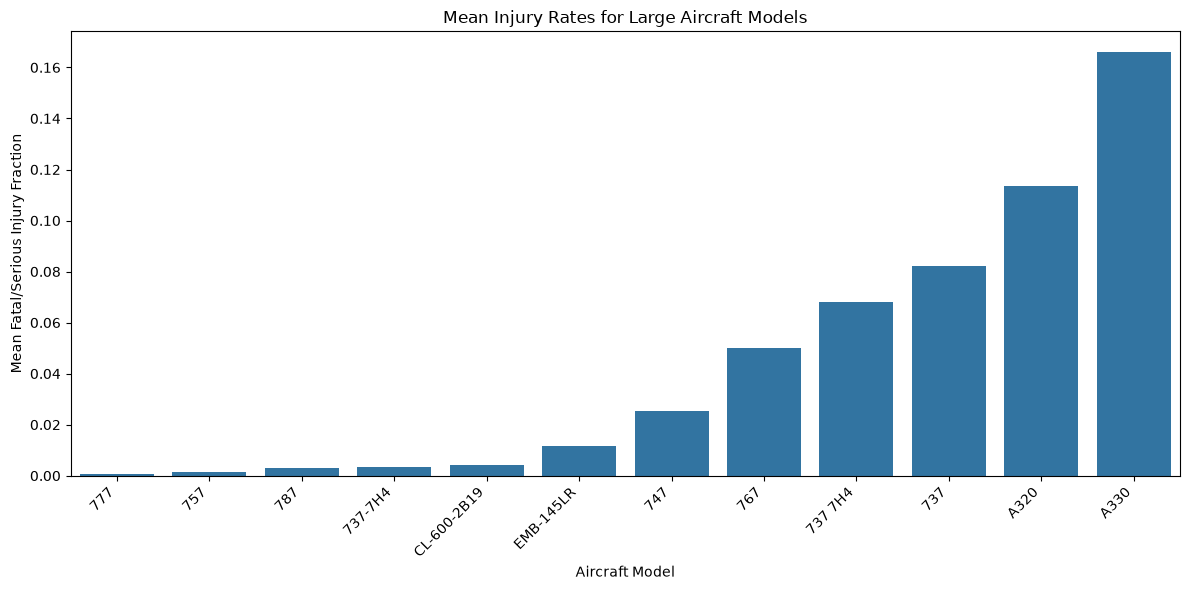

,Make,Model,mean,count
130,BOEING,777,0.000589,31
101,BOEING,757,0.001560,17
144,BOEING,787,0.003058,11
78,BOEING,737-7H4,0.003537,11
165,BOMBARDIER INC,CL-600-2B19,0.004136,15
191,EMBRAER,EMB-145LR,0.011538,13
93,BOEING,747,0.025478,10
114,BOEING,767,0.050201,29
60,BOEING,737 7H4,0.068121,14
45,BOEING,737,0.082232,161


In [34]:

# Calculate mean injury rate for each large aircraft model
large_model_stats = (
    large_aircraft
    .groupby(["Make", "Model"])["Fatal_Serious_Injury_Rate"]
    .agg(["mean", "count"])
    .reset_index()
)

# Keep models with at least 10 observations
large_model_stats = large_model_stats[
    large_model_stats["count"] >= 10
]

# Select the 15 models with the lowest mean injury rates
large_model_top15 = large_model_stats.sort_values(
    "mean", ascending=True
).head(15)

# Plot the results
plt.figure(figsize=(12, 6))
sns.barplot(
    data=large_model_top15,
    x="Model",
    y="mean"
)

plt.title("Mean Injury Rates for Large Aircraft Models")
plt.xlabel("Aircraft Model")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Display the summary table
large_model_top15


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

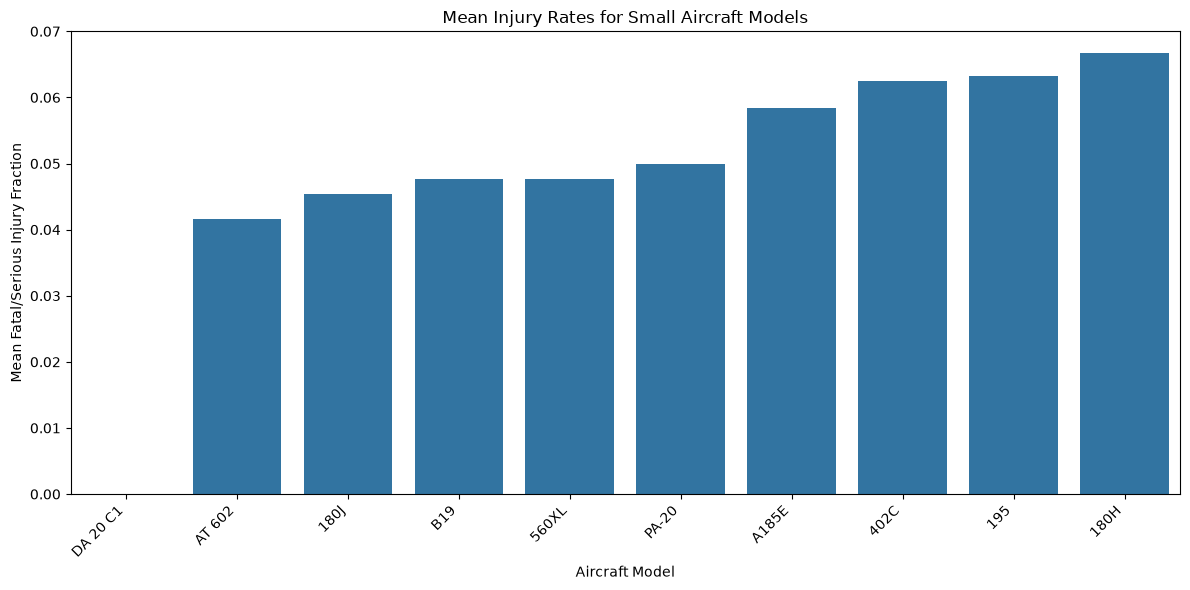

,Make,Model,mean,count
857,DIAMOND AIRCRAFT IND INC,DA 20 C1,0.000000,11
69,AIR TRACTOR,AT 602,0.041667,12
530,CESSNA,180J,0.045455,22
243,BEECH,B19,0.047619,14
663,CESSNA,560XL,0.047619,21
1211,PIPER,PA-20,0.050000,20
671,CESSNA,A185E,0.058333,12
641,CESSNA,402C,0.062500,16
565,CESSNA,195,0.063218,29
529,CESSNA,180H,0.066667,25


In [35]:

# Calculate mean injury rate for each small aircraft model
small_model_stats = (
    small_aircraft
    .groupby(["Make", "Model"])["Fatal_Serious_Injury_Rate"]
    .agg(["mean", "count"])
    .reset_index()
)

# Keep models with at least 10 observations
small_model_stats = small_model_stats[
    small_model_stats["count"] >= 10
]

# Select the 10 models with the lowest mean injury rates
small_model_top10 = small_model_stats.sort_values(
    "mean", ascending=True
).head(10)

# Plot the results
plt.figure(figsize=(12, 6))
sns.barplot(
    data=small_model_top10,
    x="Model",
    y="mean"
)

plt.title("Mean Injury Rates for Small Aircraft Models")
plt.xlabel("Aircraft Model")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Display the summary table
small_model_top10


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

- The large-aircraft model bar chart shows that the mean fatal/serious injury fractions vary considerably between models, with the Boeing 777 having one of the lowest rates (approximately 0.06%), based on 31 recorded accidents. In contrast, the Airbus A330 has the highest mean injury fraction among the displayed models (approximately 16.6%), demonstrating that injury outcomes differ across aircraft types and should be assessed alongside sample sizes and destruction rates before making recommendations.

-The small-aircraft model bar chart shows that the DA 20 C1 has the lowest mean fatal/serious injury fraction, followed by the AT-602, while the Cessna 180H has the highest rate among the ten displayed small-aircraft models at approximately 6.7%. Overall, the injury fractions range from around 4.2% to 6.7% for most displayed models, but these results should be considered alongside sample sizes and aircraft destruction rates before recommending a model as safer.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,Number.of.Engines,Mean_Injury_Fraction,Sample_Size
3,3.0,0.106367,16
4,4.0,0.141496,42
1,1.0,0.291354,10781
2,2.0,0.291999,1945


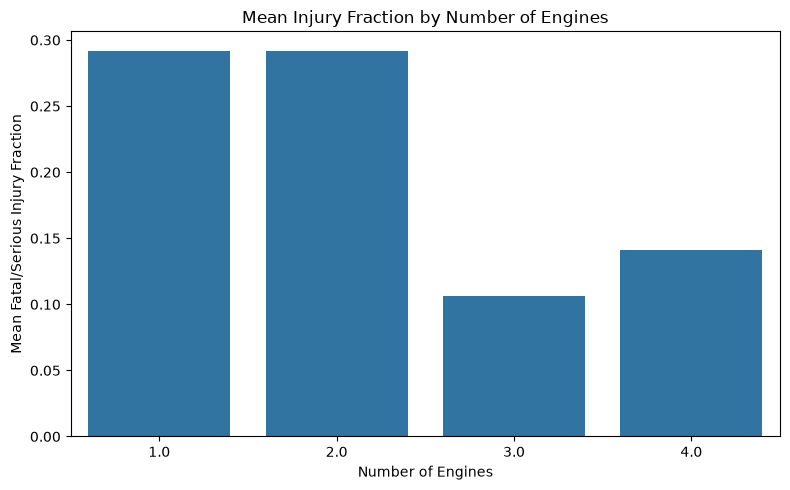

In [37]:

# Summarize injury and destruction rates by number of engines
engine_stats = (
    df.groupby("Number.of.Engines")
    .agg(
        Mean_Injury_Fraction=(
            "Fatal_Serious_Injury_Rate", "mean"
        ),
        Sample_Size=(
            "Fatal_Serious_Injury_Rate", "count"
        )
    )
    .reset_index()
)

# Keep groups with at least 10 valid accidents
engine_stats = engine_stats[
    engine_stats["Sample_Size"] >= 10
]

# Sort by mean injury fraction
engine_stats = engine_stats.sort_values(
    "Mean_Injury_Fraction"
)

display(engine_stats)

# Plot mean injury fraction
plt.figure(figsize=(8, 5))
sns.barplot(
    data=engine_stats,
    x="Number.of.Engines",
    y="Mean_Injury_Fraction"
)

plt.title("Mean Injury Fraction by Number of Engines")
plt.xlabel("Number of Engines")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.tight_layout()
plt.show()


The chart shows that aircraft with one or two engines have the highest mean injury fractions (approximately 29%), compared with about 11% for three-engine and 14% for four-engine aircraft.


,Weather.Condition,Mean_Injury_Rate,Destruction_Rate,Sample_Size
0,IMC,2.134289,0.0,875
1,UNK,1.655556,0.0,233
2,VMC,0.597639,0.0,13781


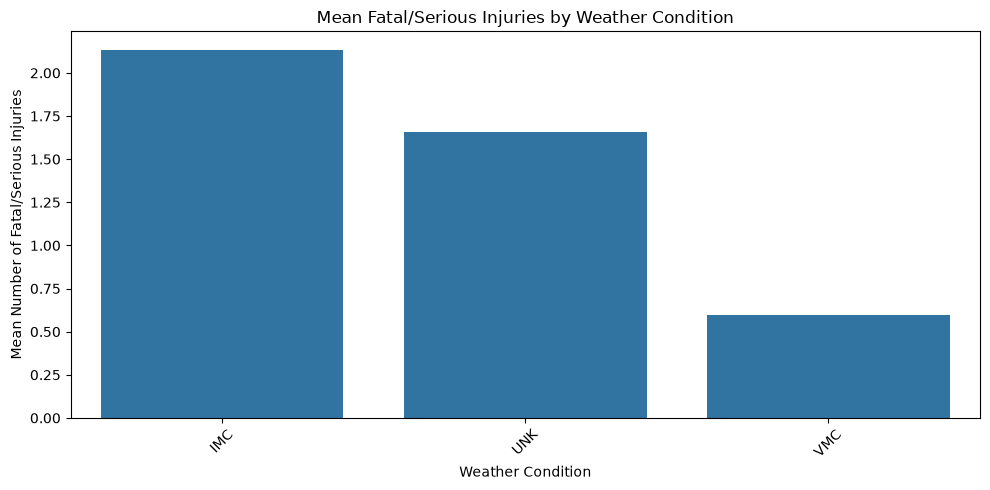

In [38]:

# Compare injury and destruction rates by weather condition
weather_stats = (
    df.groupby("Weather.Condition")
    .agg(
        Mean_Injury_Rate=("Fatal_Serious_Injuries", "mean"),
        Destruction_Rate=("Aircraft.Destroyed",
                          lambda x: (x == "Destroyed").mean()),
        Sample_Size=("Weather.Condition", "count")
    )
    .reset_index()
)

# Keep weather conditions with at least 10 records
weather_stats = weather_stats[
    weather_stats["Sample_Size"] >= 10
]

weather_stats = weather_stats.sort_values(
    "Mean_Injury_Rate", ascending=False
)

display(weather_stats)

# Visualize injury rates
plt.figure(figsize=(10, 5))
sns.barplot(
    data=weather_stats,
    x="Weather.Condition",
    y="Mean_Injury_Rate"
)

plt.title("Mean Fatal/Serious Injuries by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Mean Number of Fatal/Serious Injuries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Accidents under instrument meteorological conditions (IMC) had the highest average fatal/serious injuries (2.13), followed by unknown weather conditions (1.66) and visual meteorological conditions (VMC) (0.60), suggesting that poor visibility may be associated with more severe outcomes, although aircraft occupancy and differences in sample sizes should also be considered.